# Parts 5 to 8: Feature Engineering, Model Building, Evaluation and Interpretation
**Project:** Crop Recommendation System Using Machine Learning

The code for these stages lives in `src/` (`features.py`, `train.py`, `evaluate.py`, `interpret.py`) so the web app can reuse it. This notebook runs each stage and shows its results.
Run `python -m src.preprocess` first (Part 3) so that `data/processed/` exists. Start the notebook from the `notebooks/` folder.

In [1]:
import sys, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")
import pandas as pd
from IPython.display import Image, display
from src import features, train, evaluate, interpret, config
pd.set_option("display.width", 200)

## Part 5: Feature engineering
We tested whether (a) removing weak or redundant features or (b) adding engineered features improves **5-fold cross-validated accuracy on the training set** (Random Forest and SVM). Engineered features: `NPK_sum`, `N_P_ratio`, `N_K_ratio`, `P_K_ratio`, `temp_x_humidity`, `rainfall_per_humidity`. The test set is not used. A different set is adopted only if it beats the baseline by at least 0.2 percentage points.

In [2]:
features.main()
pd.read_csv(config.REPORTS_DIR / "feature_experiments.csv")

baseline (7 original)                  RF 0.9938 | SVM 0.9790


drop P (redundant with K)              RF 0.9909 | SVM 0.9659


drop K                                 RF 0.9886 | SVM 0.9625


drop ph and temperature (weakest)      RF 0.9898 | SVM 0.9739


baseline + NPK_sum                     RF 0.9949 | SVM 0.9784


baseline + nutrient ratios             RF 0.9938 | SVM 0.9756


baseline + all 6 engineered            RF 0.9926 | SVM 0.9795

Chosen feature set: baseline (7 original)


,feature_set,n_features,Random Forest CV acc,Random Forest CV std,SVM CV acc,SVM CV std,mean CV acc,chosen
0,baseline (7 original),7,0.9938,0.0045,0.9790,0.0103,0.9864,True
1,drop P (redundant with K),6,0.9909,0.0049,0.9659,0.0108,0.9784,False
2,drop K,6,0.9886,0.0051,0.9625,0.0101,0.9756,False
3,drop ph and temperature (weakest),5,0.9898,0.0091,0.9739,0.0133,0.9818,False
4,baseline + NPK_sum,8,0.9949,0.0049,0.9784,0.0096,0.9866,False
5,baseline + nutrient ratios,10,0.9938,0.0055,0.9756,0.0103,0.9847,False
6,baseline + all 6 engineered,13,0.9926,0.0075,0.9795,0.0105,0.9861,False


**Decision:** no alternative beat the 7 original features by the required margin. Adding `NPK_sum` gave a tiny gain for Random Forest (+0.1 pp) but none for SVM, and dropping any feature lowered accuracy for both models. We therefore keep the original seven features: they are simpler and easier for farmers to supply. The tree-based and SVM models can already learn the interactions that the ratio features try to encode. Scaling is part of every model pipeline (`StandardScaler`, fitted inside each cross-validation fold).

## Part 6: Model building
Seven classifiers were tuned with 5-fold stratified Grid Search on the training set (accuracy as the score, `random_state=42` everywhere). Each model is a pipeline of feature set, scaler and classifier. The final model is chosen by **cross-validation accuracy**, not by the test set.

In [3]:
train.main()
pd.read_csv(config.REPORTS_DIR / "model_cv_results.csv")

Logistic Regression  CV acc 0.9778 (+/- 0.0058)  {'model__C': 100}  [1s]


KNN                  CV acc 0.9682 (+/- 0.0117)  {'model__n_neighbors': 5, 'model__weights': 'distance'}  [1s]


SVM (RBF)            CV acc 0.9830 (+/- 0.0018)  {'model__C': 100, 'model__gamma': 0.1}  [5s]


Naive Bayes          CV acc 0.9949 (+/- 0.0042)  {'model__var_smoothing': 1e-09}  [0s]


Decision Tree        CV acc 0.9858 (+/- 0.0067)  {'model__max_depth': None, 'model__min_samples_split': 5}  [0s]


Random Forest        CV acc 0.9955 (+/- 0.0046)  {'model__max_depth': None, 'model__min_samples_split': 5, 'model__n_estimators': 200}  [9s]


Gradient Boosting    CV acc 0.9920 (+/- 0.0055)  {'model__learning_rate': 0.05, 'model__max_iter': 100}  [24s]



Best model by cross-validation: Random Forest


,model,best_params,cv_accuracy,cv_std,search_seconds
0,Random Forest,"{'max_depth': None, 'min_samples_split': 5, 'n...",0.9955,0.0046,9.2
1,Naive Bayes,{'var_smoothing': 1e-09},0.9949,0.0042,0.2
2,Gradient Boosting,"{'learning_rate': 0.05, 'max_iter': 100}",0.9920,0.0055,24.3
3,Decision Tree,"{'max_depth': None, 'min_samples_split': 5}",0.9858,0.0067,0.5
4,SVM (RBF),"{'C': 100, 'gamma': 0.1}",0.9830,0.0018,4.7
5,Logistic Regression,{'C': 100},0.9778,0.0058,0.8
6,KNN,"{'n_neighbors': 5, 'weights': 'distance'}",0.9682,0.0117,0.7


**Rationale for the model families**
- *Logistic Regression and KNN:* simple baselines (linear and distance-based).
- *SVM (RBF):* handles non-linear class boundaries.
- *Naive Bayes:* very fast, and suits features that are roughly independent given the crop (we found low correlation in Part 4).
- *Decision Tree, Random Forest, Gradient Boosting:* handle different feature scales and non-linear rules, and give feature importances.

## Part 7: Model evaluation (held-out test set, 440 records)

In [4]:
evaluate.main()

              Model  CV accuracy  Test accuracy  Precision (macro)  Recall (macro)  F1 (macro)  ROC-AUC (OvR)  Test errors
      Random Forest       0.9955         0.9955             0.9957          0.9955      0.9955         1.0000            2
        Naive Bayes       0.9949         0.9955             0.9959          0.9955      0.9954         1.0000            2
  Gradient Boosting       0.9920         0.9886             0.9899          0.9886      0.9887         1.0000            5
          SVM (RBF)       0.9830         0.9886             0.9894          0.9886      0.9886         1.0000            5
Logistic Regression       0.9778         0.9841             0.9852          0.9841      0.9840         0.9999            7
                KNN       0.9682         0.9818             0.9829          0.9818      0.9816         0.9987            8
      Decision Tree       0.9858         0.9795             0.9806          0.9795      0.9794         0.9905            9



Selected model: Random Forest. Misclassified 2 of 440 test records:
actual     predicted
blackgram  maize        1
rice       jute         1
Records misclassified by at least one model: 20


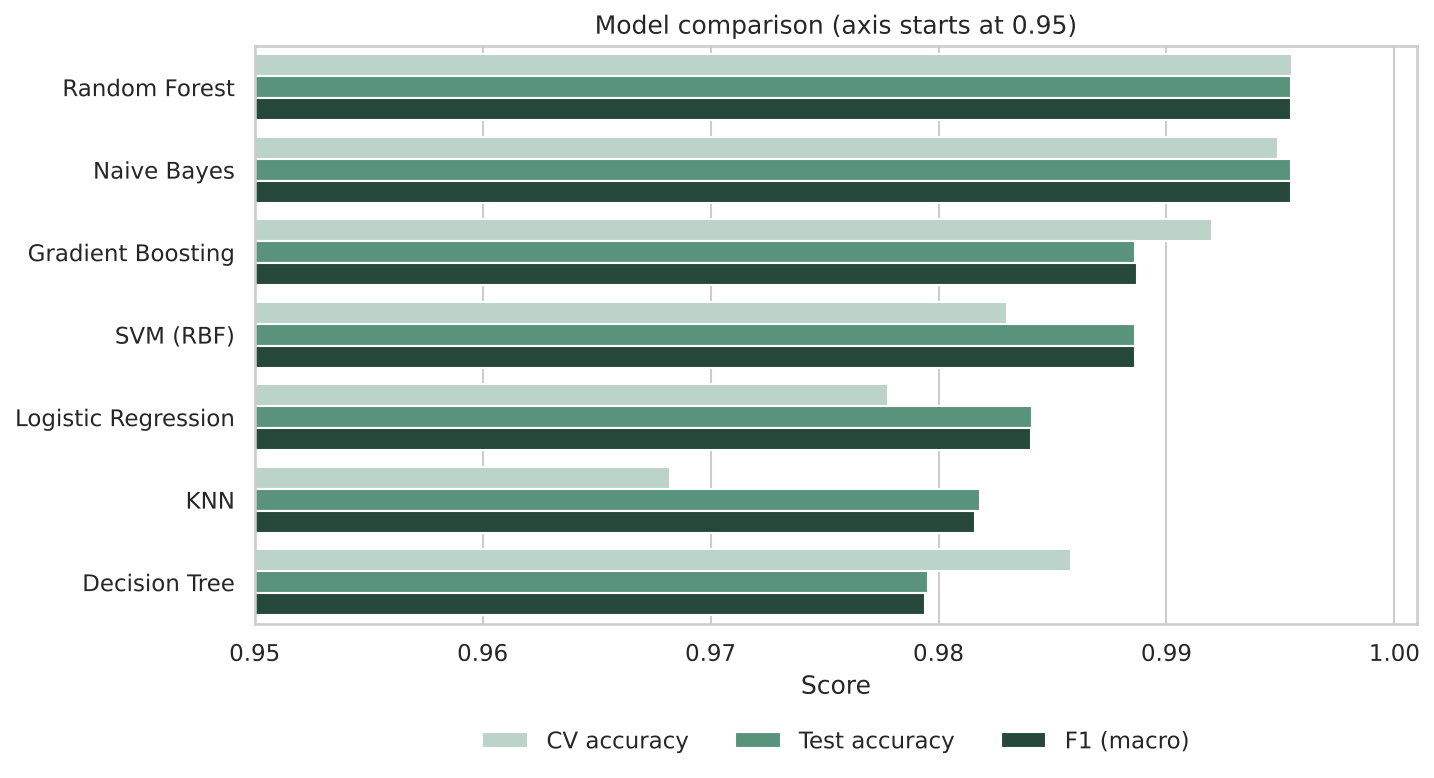

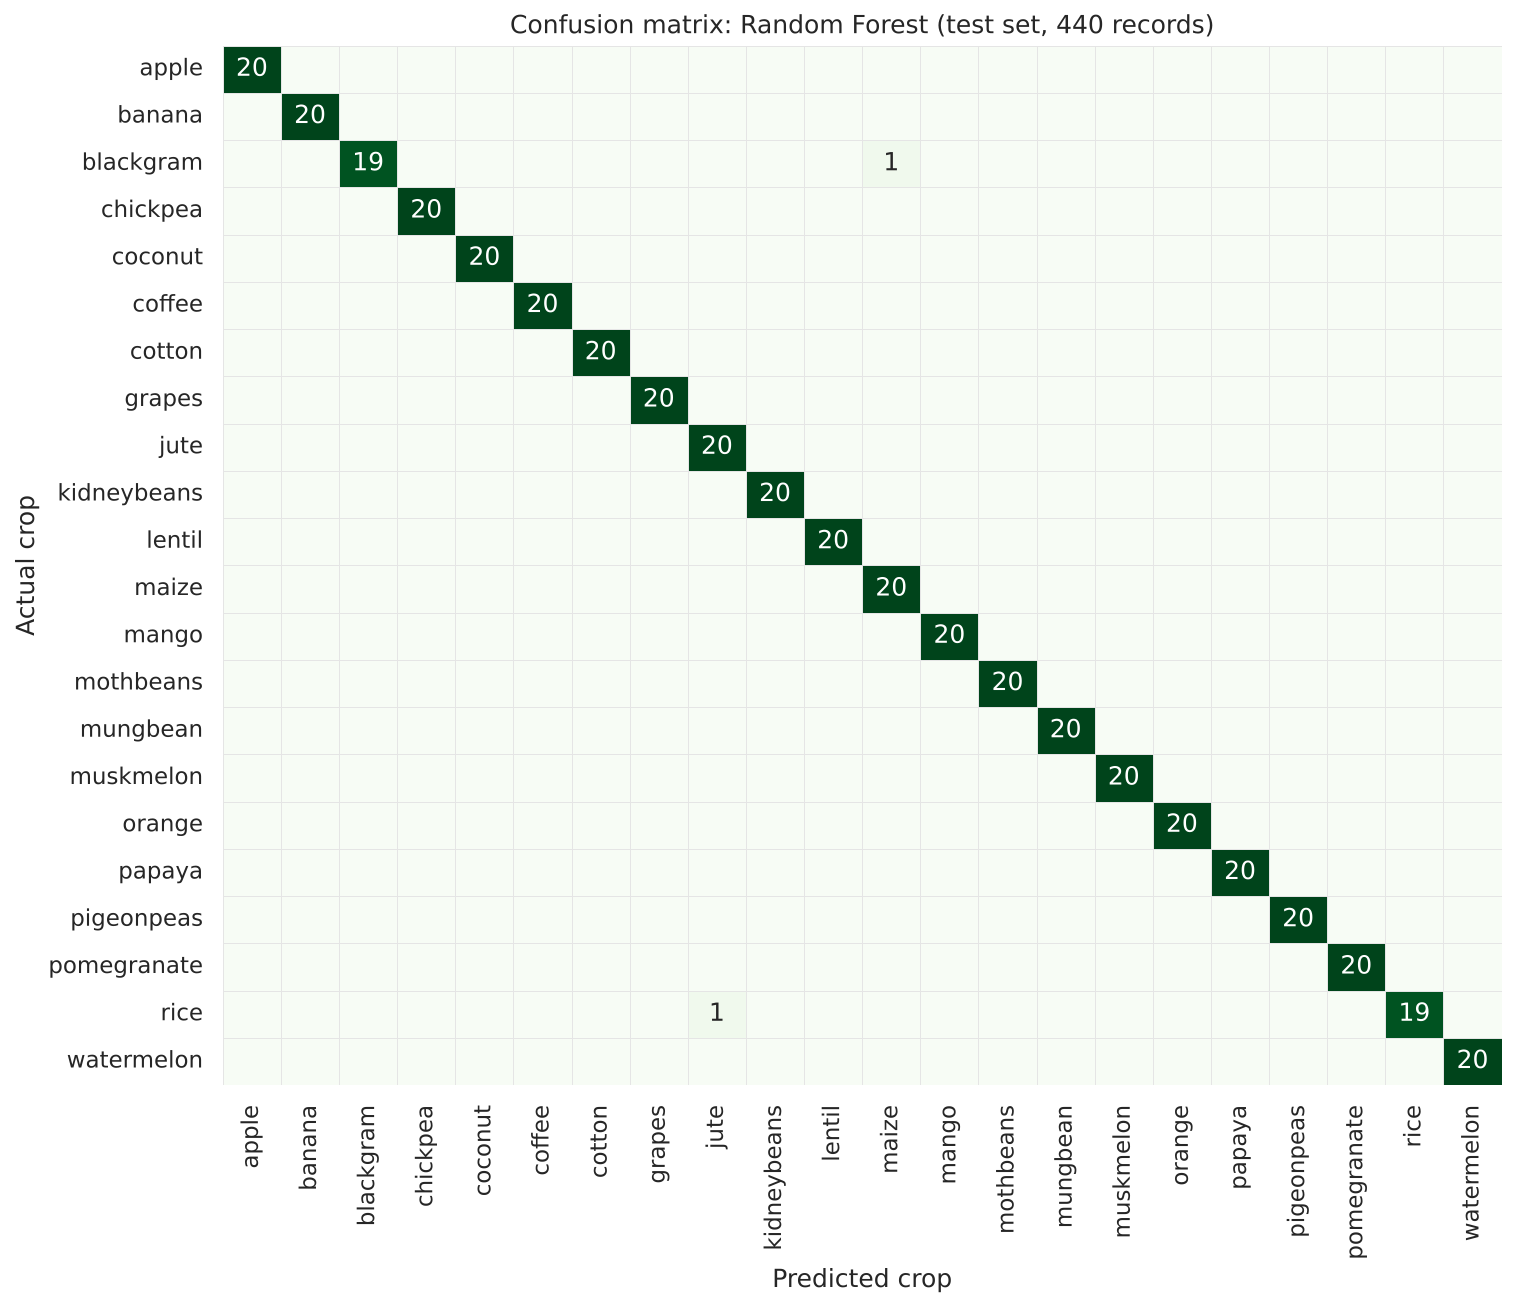

In [5]:
display(Image(str(config.REPORTS_DIR / "eval" / "fig07_model_comparison.png"), width=700))
display(Image(str(config.REPORTS_DIR / "eval" / "fig08_confusion_matrix.png"), width=700))

In [6]:
pd.read_csv(config.REPORTS_DIR / "classification_report.csv", index_col=0)

,precision,recall,f1-score,support
apple,1.000,1.000,1.000,20.000
banana,1.000,1.000,1.000,20.000
blackgram,1.000,0.950,0.974,20.000
chickpea,1.000,1.000,1.000,20.000
coconut,1.000,1.000,1.000,20.000
coffee,1.000,1.000,1.000,20.000
cotton,1.000,1.000,1.000,20.000
grapes,1.000,1.000,1.000,20.000
jute,0.952,1.000,0.976,20.000
kidneybeans,1.000,1.000,1.000,20.000


## Part 8: Results interpretation

    feature  accuracy_drop    std  impurity_importance
   humidity         0.3269 0.0190               0.2202
          N         0.2602 0.0138               0.1067
   rainfall         0.1773 0.0130               0.2208
          K         0.1502 0.0118               0.1783
          P         0.1092 0.0147               0.1488
temperature         0.0084 0.0028               0.0746
         ph         0.0077 0.0036               0.0507


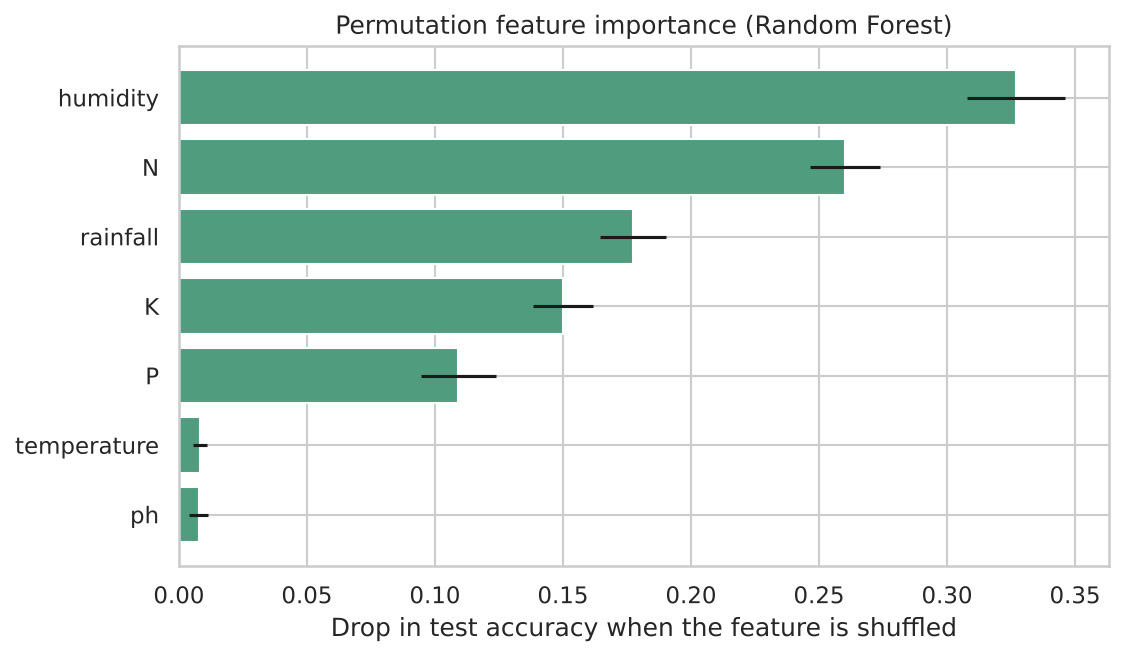

In [7]:
interpret.main()
display(Image(str(config.REPORTS_DIR / "eval" / "fig09_feature_importance.png"), width=600))

In [8]:
pd.read_csv(config.REPORTS_DIR / "crop_requirements.csv", index_col=0)

,N,P,K,temperature,humidity,ph,rainfall
label,,,,,,,
apple,0 to 40,120 to 145,195 to 205,21.0 to 24.0,90.0 to 94.9,5.5 to 6.5,100.0 to 125.0
banana,80 to 120,70 to 95,45 to 55,25.0 to 29.9,75.0 to 85.0,5.5 to 6.5,90.0 to 120.0
blackgram,20 to 60,55 to 80,15 to 25,25.1 to 34.9,60.1 to 70.0,6.5 to 7.8,60.0 to 75.0
chickpea,20 to 60,55 to 80,75 to 85,17.0 to 21.0,14.3 to 20.0,6.0 to 8.9,65.0 to 95.0
coconut,0 to 40,5 to 30,25 to 35,25.0 to 29.9,90.0 to 100.0,5.5 to 6.5,131.0 to 226.0
coffee,80 to 120,15 to 40,25 to 35,23.1 to 27.9,50.0 to 69.9,6.0 to 7.5,115.0 to 199.0
cotton,100 to 140,35 to 60,15 to 25,22.0 to 26.0,75.0 to 84.9,5.8 to 8.0,61.0 to 100.0
grapes,0 to 40,120 to 145,195 to 205,8.8 to 41.9,80.0 to 84.0,5.5 to 6.5,65.0 to 75.0
jute,60 to 100,35 to 60,35 to 45,23.1 to 27.0,70.9 to 89.9,6.0 to 7.5,150.0 to 200.0
